CSV file saved at: C:\Users\abhis\Documents\sales_data.csv

First five rows:
  Product  Sales  Quantity     Region        Date
0  Laptop  50000         2    Chennai  2026-01-01
1   Phone  20000         3  Bangalore  2026-01-02
2  Tablet  15000         1    Chennai  2026-01-03
3  Laptop  45000         2     Mumbai  2026-01-04
4   Phone  22000         4  Bangalore  2026-01-05

Missing values:
Product     0
Sales       0
Quantity    0
Region      0
Date        0
dtype: int64

Summary Statistics:
              Sales   Quantity
count     10.000000  10.000000
mean   31400.000000   2.500000
std    16015.270491   1.269296
min    15000.000000   1.000000
25%    18500.000000   2.000000
50%    23500.000000   2.000000
75%    47250.000000   3.000000
max    55000.000000   5.000000

Product Summary:
  Product   Sales  Quantity
0  Laptop  198000         9
1   Phone   67000        12
2  Tablet   49000         4


C:\Users\abhis\AppData\Local\Temp\ipykernel_1240\1520536601.py:49: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=['Product', 'Quantity', 'Region', 'Date'],


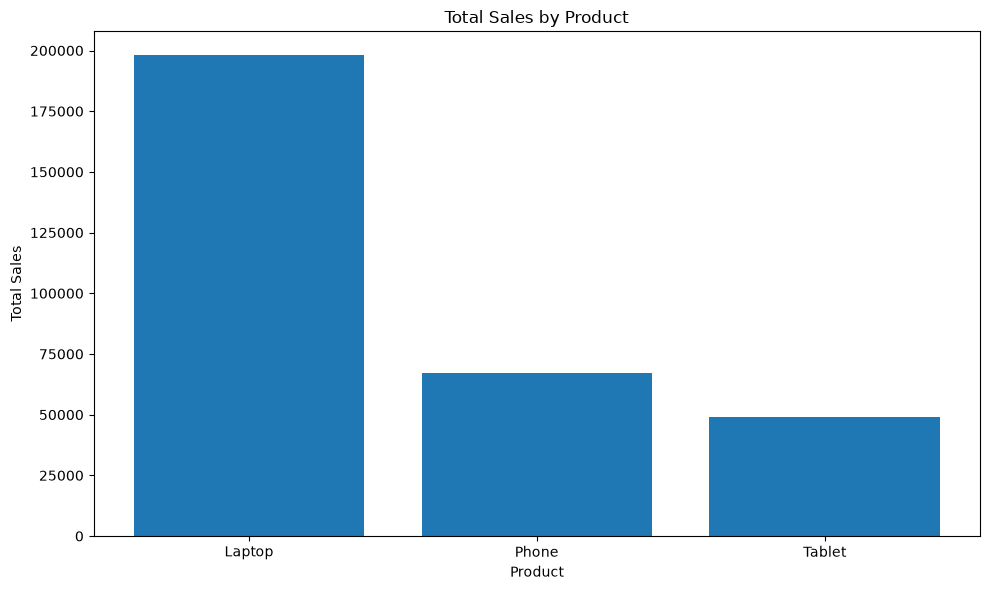

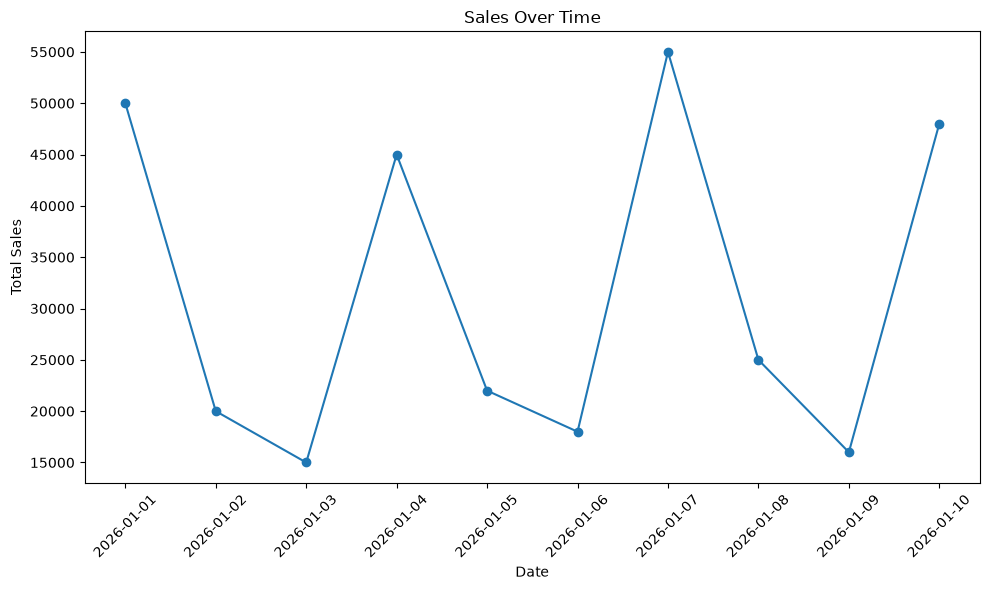


Sales by Region and Product:
Product    Laptop  Phone  Tablet
Region                          
Bangalore       0  42000   16000
Chennai    153000      0   15000
Mumbai      45000  25000   18000

Correlation Matrix:
             Sales  Quantity
Sales     1.000000  0.032795
Quantity  0.032795  1.000000


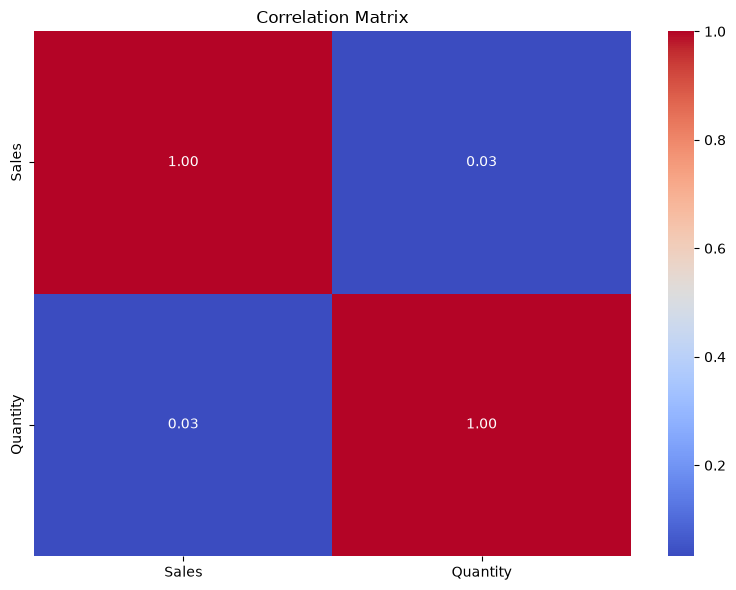


Sales data analysis completed successfully!


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Step 1: Set a safe file path
file_path = os.path.join(
    os.path.expanduser("~"),
    "Documents",
    "sales_data.csv"
)

# Create the Documents folder if it does not exist
os.makedirs(os.path.dirname(file_path), exist_ok=True)

# Step 2: Create sample sales data
data = {
    'Product': ['Laptop', 'Phone', 'Tablet', 'Laptop', 'Phone',
                'Tablet', 'Laptop', 'Phone', 'Tablet', 'Laptop'],
    'Sales': [50000, 20000, 15000, 45000, 22000,
              18000, 55000, 25000, 16000, 48000],
    'Quantity': [2, 3, 1, 2, 4, 2, 3, 5, 1, 2],
    'Region': ['Chennai', 'Bangalore', 'Chennai', 'Mumbai',
               'Bangalore', 'Mumbai', 'Chennai', 'Mumbai',
               'Bangalore', 'Chennai'],
    'Date': ['2026-01-01', '2026-01-02', '2026-01-03',
             '2026-01-04', '2026-01-05', '2026-01-06',
             '2026-01-07', '2026-01-08', '2026-01-09',
             '2026-01-10']
}

# Step 3: Save the data
sample_df = pd.DataFrame(data)
sample_df.to_csv(file_path, index=False)
print("CSV file saved at:", file_path)

# Step 4: Load the CSV file
df = pd.read_csv(file_path)
print("\nFirst five rows:")
print(df.head())

# Step 5: Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Step 6: Handle missing values
df['Sales'] = df['Sales'].fillna(df['Sales'].mean())
df.dropna(subset=['Product', 'Quantity', 'Region', 'Date'],
          inplace=True)

# Step 7: Summary statistics
print("\nSummary Statistics:")
print(df.describe())

# Step 8: Group by product
product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()

print("\nProduct Summary:")
print(product_summary)

# Step 9: Bar chart
plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.tight_layout()
plt.show()

# Step 10: Line chart
df['Date'] = pd.to_datetime(df['Date'])
sales_over_time = df.groupby('Date', as_index=False)['Sales'].sum()

plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'],
         marker='o')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 11: Pivot table
pivot_table = df.pivot_table(
    values='Sales',
    index='Region',
    columns='Product',
    aggfunc='sum',
    fill_value=0
)

print("\nSales by Region and Product:")
print(pivot_table)

# Step 12: Correlation matrix
correlation_matrix = df.select_dtypes(
    include='number'
).corr()

print("\nCorrelation Matrix:")
print(correlation_matrix)

# Step 13: Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True,
            cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

print("\nSales data analysis completed successfully!")
